# Kiva loan amount

## Mission and use case

My mission is to help women and rural micro-entrepreneurs get a fair working-capital offer through Kiva field partners. Before a loan is posted, a loan officer has to choose the US dollar amount to request. Too high, and the loan is slow to fund and hard to repay. Too low, and the business is short of capital.

This notebook predicts `loan_amount` for one borrower group. The person who uses the prediction is a Kiva field-partner loan officer, as a recommended request size before posting. The inputs are things that officer can know at posting time: the business, the group, the repayment terms, the local Multidimensional Poverty Index, and how rural the community is.

The target is a continuous amount in US dollars. House prices and other tutorial datasets are not used.


## Dataset

Source: [Data Science for Good: Kiva Crowdfunding](https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding).

Four files are joined:

- `kiva_loans.csv` has one row per loan. It supplies the target and the borrower, sector, country, term, and repayment interval.
- `kiva_mpi_region_locations.csv` has the Multidimensional Poverty Index by region. I average it to country level and attach it to each loan.
- `loan_theme_ids.csv` links a loan id to a Kiva loan theme.
- `loan_themes_by_region.csv` supplies the theme name and the rural population percentage for that theme and country.

The raw loan file has 671,205 rows. The modeling sample below is smaller so the saved forest fits in Render's free 512 MB instance. The counts, the plots, and the column choices use the full prepared file.


In [1]:
from pathlib import Path
import json
import sys
import warnings
from itertools import product

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

NOTEBOOK_DIR = Path.cwd().resolve()
candidates = [
    NOTEBOOK_DIR.parent / "API",
    NOTEBOOK_DIR / "API",
    NOTEBOOK_DIR / "summative" / "API",
]
API_DIR = next((path for path in candidates if (path / "model_io.py").exists()), None)
if API_DIR is None:
    raise FileNotFoundError(f"Could not find API/model_io.py from {NOTEBOOK_DIR}")

sys.path.insert(0, str(API_DIR))
from model_io import FEATURES, MODEL_PATH, TARGET, TRAIN_PATH, predict_one_test_row

DATA_DIR = Path.home() / "Desktop" / "archive"
if not (DATA_DIR / "kiva_loans.csv").exists():
    raise FileNotFoundError("Expected the four Kiva CSVs in Desktop/archive.")

NUMERIC = [
    "term_in_months",
    "borrower_count",
    "female_borrower_share",
    "mpi",
    "rural_pct",
]
CATEGORICAL = [
    "country",
    "sector",
    "activity",
    "repayment_interval",
    "loan_theme_type",
]
if set(NUMERIC + CATEGORICAL) != set(FEATURES):
    raise RuntimeError("Notebook features do not match API/model_io.py.")

RANDOM_STATE = 42
SAMPLE_SIZE = 30000
print("API directory:", API_DIR)
print("Data directory:", DATA_DIR)


API directory: C:\Users\HP\Documents\LinearRegression\summative\API
Data directory: C:\Users\HP\Desktop\archive


In [2]:
loans_path = DATA_DIR / "kiva_loans.csv"
mpi_path = DATA_DIR / "kiva_mpi_region_locations.csv"
theme_path = DATA_DIR / "loan_theme_ids.csv"
region_path = DATA_DIR / "loan_themes_by_region.csv"

print("All kiva_loans columns:")
print(pd.read_csv(loans_path, nrows=0).columns.tolist())

loans = pd.read_csv(
    loans_path,
    usecols=[
        "id",
        "funded_amount",
        "loan_amount",
        "activity",
        "sector",
        "country",
        "term_in_months",
        "lender_count",
        "borrower_genders",
        "repayment_interval",
    ],
)
mpi = pd.read_csv(mpi_path, usecols=["country", "MPI"])
themes = pd.read_csv(theme_path, usecols=["id", "Loan Theme ID", "Loan Theme Type"])
regions = pd.read_csv(region_path, usecols=["Loan Theme ID", "country", "rural_pct"])

print("kiva_loans", loans.shape)
print("kiva_mpi_region_locations", mpi.shape)
print("loan_theme_ids", themes.shape)
print("loan_themes_by_region", regions.shape)
loans.head(3)


All kiva_loans columns:
['id', 'funded_amount', 'loan_amount', 'activity', 'sector', 'use', 'country_code', 'country', 'region', 'currency', 'partner_id', 'posted_time', 'disbursed_time', 'funded_time', 'term_in_months', 'lender_count', 'tags', 'borrower_genders', 'repayment_interval', 'date']


kiva_loans (671205, 10)
kiva_mpi_region_locations (2772, 2)
loan_theme_ids (779092, 3)
loan_themes_by_region (15736, 3)


,id,funded_amount,loan_amount,activity,sector,country,term_in_months,lender_count,borrower_genders,repayment_interval
0,653051,300.0,300.0,Fruits & Vegetables,Food,Pakistan,12.0,12,female,irregular
1,653053,575.0,575.0,Rickshaw,Transportation,Pakistan,11.0,14,"female, female",irregular
2,653068,150.0,150.0,Transportation,Transportation,India,43.0,6,female,bullet


## Prepare the modeling table

`borrower_genders` is a comma-separated list such as `female, female`. I turn it into the size of the group and the share of women. Country-level MPI comes from the region poverty file. Theme type and rural percentage come from the theme id file joined to the theme-by-region file.

`funded_amount` and `lender_count` are loaded only so the heatmap can show why they must not be used as inputs.


In [3]:
n_raw_loans = len(loans)
work = loans.copy()
gender = work["borrower_genders"].fillna("").str.lower()
work["borrower_count"] = np.where(gender.str.len() > 0, gender.str.count(",") + 1, 0)
work["female_count"] = gender.str.count("female")
dropped_missing_gender = int((work["borrower_count"] == 0).sum())
work = work.loc[work["borrower_count"] > 0].copy()
work["female_borrower_share"] = work["female_count"] / work["borrower_count"]
work["country"] = work["country"].astype(str).str.strip()
work["sector"] = work["sector"].astype(str).str.strip()
work["activity"] = work["activity"].astype(str).str.strip()
work["repayment_interval"] = work["repayment_interval"].astype(str).str.strip().str.lower()

country_mpi = (
    mpi.dropna(subset=["country", "MPI"])
    .assign(country=lambda frame: frame["country"].astype(str).str.strip())
    .groupby("country")["MPI"]
    .mean()
)
work["mpi"] = work["country"].map(country_mpi)
mpi_coverage = float(work["mpi"].notna().mean())
mpi_median = float(work["mpi"].median())
work["mpi"] = work["mpi"].fillna(mpi_median)

themes = themes.drop_duplicates("id").copy()
themes["Loan Theme ID"] = themes["Loan Theme ID"].astype("string")
regions = regions.copy()
regions["Loan Theme ID"] = regions["Loan Theme ID"].astype("string")
regions["country"] = regions["country"].astype("string").str.strip()
rural_by_country = (
    regions.dropna(subset=["rural_pct"])
    .groupby(["Loan Theme ID", "country"], as_index=False)["rural_pct"]
    .mean()
)
rural_by_theme = regions.groupby("Loan Theme ID")["rural_pct"].mean()

work = work.merge(themes, on="id", how="left")
work = work.merge(rural_by_country, on=["Loan Theme ID", "country"], how="left")
if not work["id"].is_unique:
    raise RuntimeError("Join duplicated loan ids.")
rural_country_match = float(work["rural_pct"].notna().mean())
missing_rural = work["rural_pct"].isna()
work.loc[missing_rural, "rural_pct"] = work.loc[missing_rural, "Loan Theme ID"].map(rural_by_theme)
rural_median = float(work["rural_pct"].median())
still_missing_rural = int(work["rural_pct"].isna().sum())
work["rural_pct"] = work["rural_pct"].fillna(rural_median)
work["loan_theme_type"] = work["Loan Theme Type"].fillna("General").astype(str).str.strip()

eda = work[
    [
        "funded_amount",
        "loan_amount",
        "lender_count",
        "activity",
        "sector",
        "country",
        "repayment_interval",
        "loan_theme_type",
        "term_in_months",
        "borrower_count",
        "female_borrower_share",
        "mpi",
        "rural_pct",
    ]
].copy()

print(f"Raw loans: {n_raw_loans:,}")
print(f"Dropped for missing borrower gender: {dropped_missing_gender:,}")
print(f"Rows in the prepared table: {len(eda):,}")
print(f"Share of loans with a country MPI match: {mpi_coverage:.1%}")
print(f"Median MPI used where the country was missing: {mpi_median:.3f}")
print(f"Share of loans with rural_pct matched on theme and country: {rural_country_match:.1%}")
print(f"Rows whose rural_pct fell back to the overall median: {still_missing_rural:,}")
print("Equal funded_amount and loan_amount:", f"{(eda['funded_amount'] == eda['loan_amount']).mean():.1%}")
eda[FEATURES + [TARGET, "funded_amount", "lender_count"]].head(3)


Raw loans: 671,205
Dropped for missing borrower gender: 4,221
Rows in the prepared table: 666,984
Share of loans with a country MPI match: 82.5%
Median MPI used where the country was missing: 0.062
Share of loans with rural_pct matched on theme and country: 88.1%
Rows whose rural_pct fell back to the overall median: 79,101
Equal funded_amount and loan_amount: 92.9%


,country,sector,activity,repayment_interval,loan_theme_type,term_in_months,borrower_count,female_borrower_share,mpi,rural_pct,loan_amount,funded_amount,lender_count
0,Pakistan,Food,Fruits & Vegetables,irregular,General,12.0,1,1.0,0.233167,69.0,300.0,300.0,12
1,Pakistan,Transportation,Rickshaw,irregular,Underserved,11.0,2,1.0,0.233167,0.0,575.0,575.0,14
2,India,Transportation,Transportation,bullet,Underserved,43.0,1,1.0,0.061824,82.0,150.0,150.0,6


## Visualizations that drive the model

The heatmap includes two columns I expect to leak the target. The histograms show the scale of the amount and the term. The bar chart checks whether sector changes the typical amount.


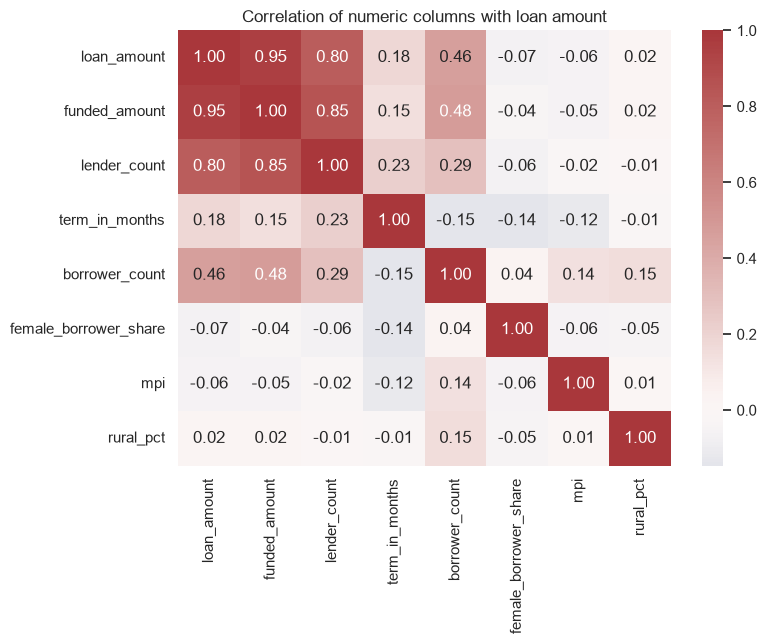

funded_amount            0.952
lender_count             0.803
borrower_count           0.463
term_in_months           0.184
female_borrower_share   -0.069
mpi                     -0.058
rural_pct                0.020

The strongest linear association with loan amount is funded_amount at 0.95. funded_amount and lender_count move with the target because they are results of funding, not facts the officer has when setting the request. I drop both. Term, borrower count, the share of women, MPI, and rural share stay, because they are known at posting time. A small linear correlation does not by itself remove a column: a tree can still use it in a split, and MPI and rural share are part of the decision the officer is making.


In [4]:
heat_columns = [
    "loan_amount",
    "funded_amount",
    "lender_count",
    "term_in_months",
    "borrower_count",
    "female_borrower_share",
    "mpi",
    "rural_pct",
]
corr = eda[heat_columns].corr()
fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of numeric columns with loan amount")
fig.tight_layout()
plt.show()

with_target = corr["loan_amount"].drop(labels=["loan_amount"])
with_target = with_target.reindex(with_target.abs().sort_values(ascending=False).index)
print(with_target.round(3).to_string())
print()
print(
    f"The strongest linear association with loan amount is {with_target.index[0]} "
    f"at {with_target.iloc[0]:.2f}. "
    "funded_amount and lender_count move with the target because they are results of funding, not facts the officer has when setting the request. "
    "I drop both. Term, borrower count, the share of women, MPI, and rural share stay, because they are known at posting time. "
    "A small linear correlation does not by itself remove a column: a tree can still use it in a split, and MPI and rural share are part of the decision the officer is making."
)


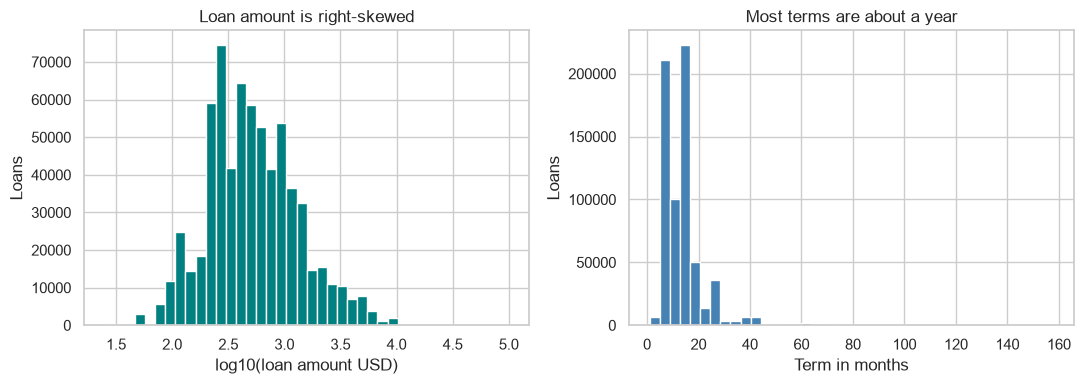

The log histogram shows the request spread over more than an order of magnitude. The median amount is 500 USD and the maximum is 100000 USD. Squared error would be dominated by a few very large loans, so I cap the target at the 99th percentile, 5600 USD, before training. Term is concentrated around a median of 13 months, so I keep it as a numeric input with the observed range.


In [5]:
amount_cap = float(eda["loan_amount"].quantile(0.99))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log10(eda["loan_amount"]), bins=40, color="teal")
axes[0].set_xlabel("log10(loan amount USD)")
axes[0].set_ylabel("Loans")
axes[0].set_title("Loan amount is right-skewed")
axes[1].hist(eda["term_in_months"], bins=40, color="steelblue")
axes[1].set_xlabel("Term in months")
axes[1].set_ylabel("Loans")
axes[1].set_title("Most terms are about a year")
fig.tight_layout()
plt.show()
print(
    f"The log histogram shows the request spread over more than an order of magnitude. "
    f"The median amount is {eda['loan_amount'].median():.0f} USD and the maximum is {eda['loan_amount'].max():.0f} USD. "
    f"Squared error would be dominated by a few very large loans, so I cap the target at the 99th percentile, {amount_cap:.0f} USD, before training. "
    f"Term is concentrated around a median of {eda['term_in_months'].median():.0f} months, so I keep it as a numeric input with the observed range."
)


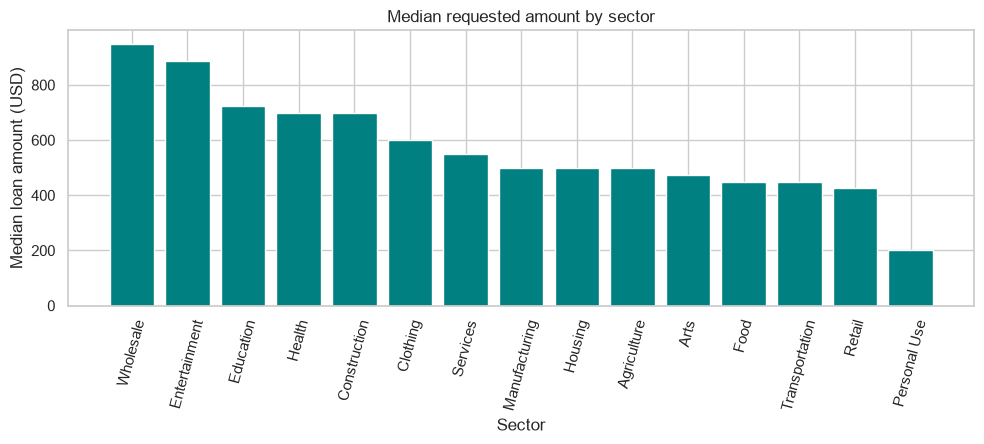

Median loan amount runs from Personal Use at 200 USD to Wholesale at 950 USD. Sector changes the amount borrowers receive, so it stays as a categorical feature. A model that ignored sector would offer one typical amount to farmers and to education borrowers.


In [6]:
medians = eda.groupby("sector")["loan_amount"].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(medians.index.astype(str), medians.values, color="teal")
ax.set_ylabel("Median loan amount (USD)")
ax.set_xlabel("Sector")
ax.set_title("Median requested amount by sector")
ax.tick_params(axis="x", rotation=75)
fig.tight_layout()
plt.show()
print(
    f"Median loan amount runs from {medians.index[-1]} at {medians.iloc[-1]:.0f} USD "
    f"to {medians.index[0]} at {medians.iloc[0]:.0f} USD. "
    "Sector changes the amount borrowers receive, so it stays as a categorical feature. "
    "A model that ignored sector would offer one typical amount to farmers and to education borrowers."
)


## Feature engineering

Columns dropped, and why:

- `id`: a row identifier.
- `funded_amount`: equal to `loan_amount` on most rows. The heatmap shows it leaking the target.
- `lender_count`: known only after lenders fund the loan, and strongly tied to the amount.
- `use` and `tags`: free text. Tags are missing on about a quarter of rows.
- `country_code` and `currency`: they repeat the country.
- `partner_id`: an identifier of the field partner, not of the business.
- `region`: missing on about 8% of rows and spelled inconsistently.
- `posted_time`, `disbursed_time`, `funded_time`, `date`: timestamps. `funded_time` is empty when a loan never funds, so it leaks the outcome.
- `borrower_genders`: replaced by `borrower_count` and `female_borrower_share`.

Columns kept as model inputs:

- numeric: `term_in_months`, `borrower_count`, `female_borrower_share`, `mpi`, `rural_pct`
- categorical: `country`, `sector`, `activity`, `repayment_interval`, `loan_theme_type`

The features that matter most for the target, before any model is fit, are the ones with a visible link in the plots: sector (the medians differ), and whichever numeric column leads the heatmap after the leaked columns are ignored. The saved model's importances later in this notebook are the check on that choice. Country and activity stay as well because a loan officer prices a farm in Kenya differently from a shop in the Philippines, even when a single linear correlation cannot show that interaction.

Countries missing from the MPI file, including some large ones, get the median MPI. That weakens the poverty signal for those countries rather than dropping the loans.


In [7]:
def stratified_sample(frame, n, seed):
    counts = frame["sector"].value_counts()
    raw = (counts / counts.sum() * n).round().astype(int).clip(lower=1)
    while int(raw.sum()) > n:
        donor = raw.idxmax()
        if int(raw.loc[donor]) <= 1:
            break
        raw.loc[donor] = int(raw.loc[donor]) - 1
    parts = []
    for sector, group in frame.groupby("sector"):
        take = min(int(raw.loc[sector]), len(group))
        parts.append(group.sample(n=take, random_state=seed))
    out = pd.concat(parts, ignore_index=True)
    return out.sample(frac=1.0, random_state=seed).reset_index(drop=True)

before_cap = len(eda)
modeling = eda.loc[eda["loan_amount"] <= amount_cap, FEATURES + [TARGET]].copy()
removed = before_cap - len(modeling)
sampled = stratified_sample(modeling, SAMPLE_SIZE, RANDOM_STATE)
for column in CATEGORICAL:
    sampled[column] = sampled[column].astype(str)
for column in NUMERIC:
    sampled[column] = sampled[column].astype(float)

print(f"Capped loan_amount at {amount_cap:.0f} USD and removed {removed:,} rows.")
print(f"Rows available after the cap: {len(modeling):,}")
print(f"Stratified modeling sample: {len(sampled):,} rows, {len(FEATURES)} features.")
print("Categorical cardinality in the sample:")
print(sampled[CATEGORICAL].nunique().to_string())
print("Numeric summary:")
print(sampled[NUMERIC + [TARGET]].describe().round(2).to_string())


Capped loan_amount at 5600 USD and removed 6,635 rows.
Rows available after the cap: 660,349
Stratified modeling sample: 30,000 rows, 10 features.
Categorical cardinality in the sample:
country                76
sector                 15
activity              154
repayment_interval      4
loan_theme_type       158
Numeric summary:
       term_in_months  borrower_count  female_borrower_share       mpi  rural_pct  loan_amount
count        30000.00        30000.00               30000.00  30000.00   30000.00     30000.00
mean            13.64            1.96                   0.77      0.13      66.48       773.11
std              8.27            3.25                   0.41      0.11      28.20       860.86
min              1.00            1.00                   0.00      0.01       0.00        25.00
25%              8.00            1.00                   0.80      0.06      60.00       275.00
50%             13.00            1.00                   1.00      0.06      69.00       500.00
75

## Train and test, then convert categories and standardize

The holdout is 20% of the modeling sample, with `random_state=42`. Categorical columns are converted to numeric with `OneHotEncoder`. A category that is rare in training is grouped, and a category that appears only later is mapped to that infrequent group when it exists.

`StandardScaler` is the next step in the same pipeline. It is fit on the training rows only. The test rows are transformed with that fit and never used to estimate the mean or the scale.


In [8]:
def make_preprocess():
    encoder = OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        sparse_output=False,
        max_categories=16,
    )
    return Pipeline(
        steps=[
            (
                "encode",
                ColumnTransformer(
                    transformers=[
                        ("numeric", "passthrough", NUMERIC),
                        ("categorical", encoder, CATEGORICAL),
                    ]
                ),
            ),
            ("scale", StandardScaler()),
        ]
    )

def make_model_pipeline(estimator):
    return Pipeline(
        steps=[
            ("preprocess", make_preprocess()),
            ("model", estimator),
        ]
    )

X = sampled[FEATURES]
y = sampled[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
preprocess = make_preprocess()
Xtr = preprocess.fit_transform(X_train)
Xte = preprocess.transform(X_test)
ytr = y_train.to_numpy()
yte = y_test.to_numpy()
print(f"Train rows: {len(X_train):,}. Test rows: {len(X_test):,}.")
print(
    f"The encoder and scaler were fit on the training rows only. "
    f"Each row is now {Xtr.shape[1]} standardized numeric columns."
)


Train rows: 24,000. Test rows: 6,000.
The encoder and scaler were fit on the training rows only. Each row is now 72 standardized numeric columns.


## Tune SGDRegressor

The gradient-descent linear model is tuned over the learning-rate schedule, the initial learning rate `eta0`, the L2 strength `alpha`, and the number of epochs. Every setting is scored with mean squared error on the same transformed test set.


In [9]:
records = []
for learning_rate, eta0, alpha, epochs in product(
    ("constant", "invscaling", "adaptive"),
    (0.001, 0.01, 0.1),
    (0.0001, 0.01),
    (15, 40),
):
    candidate = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        learning_rate=learning_rate,
        eta0=eta0,
        alpha=alpha,
        max_iter=epochs,
        tol=None,
        random_state=RANDOM_STATE,
        shuffle=True,
    )
    try:
        candidate.fit(Xtr, ytr)
        train_pred = candidate.predict(Xtr)
        test_pred = candidate.predict(Xte)
        if not np.isfinite(train_pred).all() or not np.isfinite(test_pred).all():
            raise ValueError("non-finite predictions")
        train_score = float(mean_squared_error(ytr, train_pred))
        test_score = float(mean_squared_error(yte, test_pred))
    except Exception as exc:
        print(f"Skipped learning_rate={learning_rate} eta0={eta0} alpha={alpha} epochs={epochs}: {exc}")
        train_score = float("inf")
        test_score = float("inf")
    records.append(
        {
            "learning_rate": learning_rate,
            "eta0": eta0,
            "alpha": alpha,
            "max_iter": epochs,
            "train_mse": train_score,
            "test_mse": test_score,
        }
    )

grid = pd.DataFrame(records).sort_values(["test_mse", "train_mse"]).reset_index(drop=True)
chosen = grid.iloc[0]
finite = grid.loc[grid["test_mse"] < np.inf]
print("Lowest test MSE for each learning-rate schedule")
print(finite.groupby("learning_rate")["test_mse"].min().round(1).to_string())
print("Lowest test MSE for each eta0")
print(finite.groupby("eta0")["test_mse"].min().round(1).to_string())
print("Lowest test MSE for each alpha")
print(finite.groupby("alpha")["test_mse"].min().round(1).to_string())
print("Lowest test MSE for each epoch count")
print(finite.groupby("max_iter")["test_mse"].min().round(1).to_string())
print()
print("Chosen SGDRegressor settings, the row with the lowest test MSE:")
print(chosen.to_string())
print()
preview = grid.head(8).copy()
preview["train_mse"] = preview["train_mse"].round(1)
preview["test_mse"] = preview["test_mse"].round(1)
print(preview.to_string(index=False))


Lowest test MSE for each learning-rate schedule
learning_rate
adaptive      311598.7
constant      311598.7
invscaling    305422.7
Lowest test MSE for each eta0
eta0
0.001    3.054227e+05
0.010    3.077801e+05
0.100    3.847708e+21
Lowest test MSE for each alpha
alpha
0.0001    305422.7
0.0100    305514.0
Lowest test MSE for each epoch count
max_iter
15    305549.1
40    305422.7

Chosen SGDRegressor settings, the row with the lowest test MSE:
learning_rate       invscaling
eta0                     0.001
alpha                   0.0001
max_iter                    40
train_mse        339946.110339
test_mse         305422.742473

learning_rate  eta0  alpha  max_iter  train_mse  test_mse
   invscaling 0.001 0.0001        40   339946.1  305422.7
   invscaling 0.001 0.0100        40   340019.4  305514.0
   invscaling 0.001 0.0001        15   340000.6  305549.1
   invscaling 0.001 0.0100        15   340084.9  305661.4
   invscaling 0.010 0.0100        40   343365.9  307780.1
   invscaling 0.0

## Loss curve

scikit-learn does not record train and test loss on each epoch. The loop below calls `partial_fit` once per epoch and stores both mean squared errors. The hyperparameters are the chosen row from the grid.


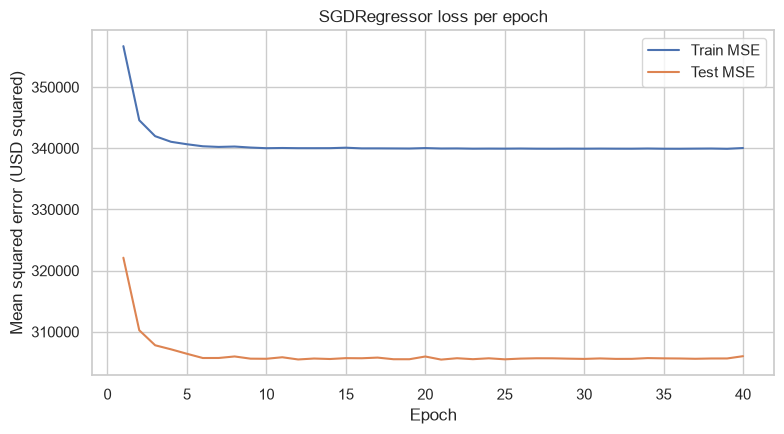

Train and test MSE are stored after every epoch because SGDRegressor.fit does not record them. Test MSE fell from 322,112 after epoch 1 to 306,019 after epoch 40. Train MSE ends at 340,039. The learning rate, regularization, and epoch count are the grid row with the lowest test MSE. Training loss does not pull away below the test loss, so this linear model is limited by the straight-line form more than by memorizing the sample.


In [10]:
sgd_curve = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    learning_rate=str(chosen["learning_rate"]),
    eta0=float(chosen["eta0"]),
    alpha=float(chosen["alpha"]),
    max_iter=1,
    tol=None,
    random_state=RANDOM_STATE,
    shuffle=True,
)
train_curve = []
test_curve = []
rng = np.random.default_rng(RANDOM_STATE)
for _epoch in range(int(chosen["max_iter"])):
    order = rng.permutation(len(Xtr))
    sgd_curve.partial_fit(Xtr[order], ytr[order])
    train_curve.append(float(mean_squared_error(ytr, sgd_curve.predict(Xtr))))
    test_curve.append(float(mean_squared_error(yte, sgd_curve.predict(Xte))))

fig, ax = plt.subplots(figsize=(8, 4.5))
epochs = np.arange(1, len(train_curve) + 1)
ax.plot(epochs, train_curve, label="Train MSE")
ax.plot(epochs, test_curve, label="Test MSE")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error (USD squared)")
ax.set_title("SGDRegressor loss per epoch")
ax.legend()
fig.tight_layout()
plt.show()
direction = "fell" if test_curve[-1] < test_curve[0] else "rose"
print(
    f"Train and test MSE are stored after every epoch because SGDRegressor.fit does not record them. "
    f"Test MSE {direction} from {test_curve[0]:,.0f} after epoch 1 to {test_curve[-1]:,.0f} after epoch {len(test_curve)}. "
    f"Train MSE ends at {train_curve[-1]:,.0f}. "
    "The learning rate, regularization, and epoch count are the grid row with the lowest test MSE. "
    "Training loss does not pull away below the test loss, so this linear model is limited by the straight-line form more than by memorizing the sample."
)


## Four models on the same test set

| Model | scikit-learn class | Why it is here |
| --- | --- | --- |
| Linear regression by gradient descent | `SGDRegressor` | The tuned linear model |
| Linear regression, closed form | `LinearRegression` | A second linear implementation |
| Decision tree | `DecisionTreeRegressor` | A tree |
| Random forest | `RandomForestRegressor` | An ensemble |

The tree and the forest use the same maximum depth (12) and the same minimum leaf size (20), so neither one can memorize a single loan. The forest is 100 trees, and each tree sees every feature. That matters here because borrower count and term carry most of the signal; a random subset of columns often drops them. The saved model is whichever of the four has the lowest test mean squared error.


In [11]:
why = {
    "SGDRegressor": "Linear model fit by gradient descent, with the tuned learning rate, regularization, and epochs.",
    "LinearRegression": "Linear model in closed form, compared with the gradient-descent fit.",
    "DecisionTreeRegressor": "A single tree, which can split on combinations of sector, country, and term.",
    "RandomForestRegressor": "An ensemble of 100 trees with the same depth and leaf size as the single tree.",
}
estimators = {
    "SGDRegressor": SGDRegressor(
        loss="squared_error",
        penalty="l2",
        learning_rate=str(chosen["learning_rate"]),
        eta0=float(chosen["eta0"]),
        alpha=float(chosen["alpha"]),
        max_iter=int(chosen["max_iter"]),
        tol=None,
        random_state=RANDOM_STATE,
        shuffle=True,
    ),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
    ),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=20,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
}

results = []
for name, estimator in estimators.items():
    pipeline = make_model_pipeline(estimator)
    pipeline.fit(X_train, y_train)
    train_mse = float(mean_squared_error(y_train, pipeline.predict(X_train)))
    test_mse = float(mean_squared_error(y_test, pipeline.predict(X_test)))
    results.append(
        {
            "model": name,
            "why": why[name],
            "train_mse": train_mse,
            "test_mse": test_mse,
            "train_rmse": float(np.sqrt(train_mse)),
            "test_rmse": float(np.sqrt(test_mse)),
            "pipeline": pipeline,
        }
    )

comparison = pd.DataFrame(results).sort_values("test_mse").reset_index(drop=True)
best_name = str(comparison.loc[0, "model"])
best_train_mse = float(comparison.loc[0, "train_mse"])
best_test_mse = float(comparison.loc[0, "test_mse"])
best_pipeline = comparison.loc[0, "pipeline"]
shown = comparison.drop(columns=["pipeline", "why"]).copy()
for column in ("train_mse", "test_mse", "train_rmse", "test_rmse"):
    shown[column] = shown[column].round(1)
print(shown.to_string(index=False))
print()
print(
    f"The best model is {best_name} because it has the lowest test MSE "
    f"({best_test_mse:,.1f}). That pipeline, including the encoder and the scaler, is the model saved for the API."
)


                model  train_mse  test_mse  train_rmse  test_rmse
RandomForestRegressor   196155.0  204146.0       442.9      451.8
DecisionTreeRegressor   198149.1  216931.7       445.1      465.8
         SGDRegressor   339946.1  305422.7       583.0      552.7
     LinearRegression   339886.2  305580.2       583.0      552.8

The best model is RandomForestRegressor because it has the lowest test MSE (204,146.0). That pipeline, including the encoder and the scaler, is the model saved for the API.


## Scatter before and after a one-feature line

The points use the numeric feature with the strongest linear correlation with the target on the training rows, ignoring the leaked columns that were dropped. The line is a separate one-feature `LinearRegression` fit for this plot only.


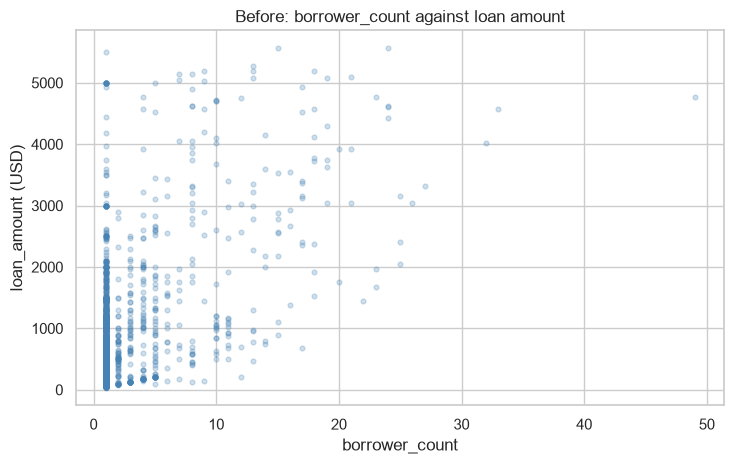

borrower_count has the strongest linear correlation with loan amount among the numeric inputs that were kept (0.52 on the training rows). The cloud has a slope, so the feature stays in the model. The vertical spread is wide, so this column alone cannot set the requested amount. The drawn points are a 3,000-row sample of the training set so the cloud is readable. The correlation uses every training row.


In [12]:
correlations = X_train[NUMERIC].corrwith(y_train).dropna()
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
best_feature = str(correlations.index[0])
feature_corr = float(correlations.iloc[0])
plot_rows = X_train.sample(n=min(3000, len(X_train)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(plot_rows[best_feature], y_train.loc[plot_rows.index], alpha=0.25, s=12, color="steelblue")
ax.set_xlabel(best_feature)
ax.set_ylabel("loan_amount (USD)")
ax.set_title(f"Before: {best_feature} against loan amount")
fig.tight_layout()
plt.show()
print(
    f"{best_feature} has the strongest linear correlation with loan amount among the numeric inputs that were kept "
    f"({feature_corr:.2f} on the training rows). "
    "The cloud has a slope, so the feature stays in the model. "
    "The vertical spread is wide, so this column alone cannot set the requested amount. "
    "The drawn points are a 3,000-row sample of the training set so the cloud is readable. The correlation uses every training row."
)


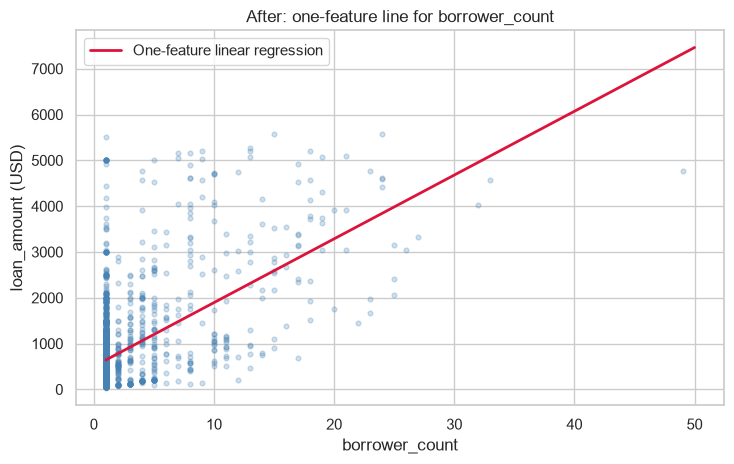

The crimson line is a one-feature linear regression fit on the training rows for this plot only. It is not the four-model comparison and it is not the saved multivariate model. The line follows the average trend and still leaves large residuals, which is why the saved model keeps the other features.


In [13]:
line = LinearRegression().fit(X_train[[best_feature]], y_train)
x_min = float(X_train[best_feature].min())
x_max = float(X_train[best_feature].max())
x_line = pd.DataFrame({best_feature: np.linspace(x_min, x_max, 100)})
y_line = line.predict(x_line)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(plot_rows[best_feature], y_train.loc[plot_rows.index], alpha=0.25, s=12, color="steelblue")
ax.plot(x_line[best_feature], y_line, color="crimson", linewidth=2, label="One-feature linear regression")
ax.set_xlabel(best_feature)
ax.set_ylabel("loan_amount (USD)")
ax.set_title(f"After: one-feature line for {best_feature}")
ax.legend()
fig.tight_layout()
plt.show()
print(
    "The crimson line is a one-feature linear regression fit on the training rows for this plot only. "
    "It is not the four-model comparison and it is not the saved multivariate model. "
    "The line follows the average trend and still leaves large residuals, which is why the saved model keeps the other features."
)


## Save the best model and predict one test row

The criterion is the lowest test mean squared error in the table above. The file is a scikit-learn `Pipeline` (encoder, scaler, and model) written with joblib. The original training rows are saved beside it so `/retrain` can refit without the raw Kaggle files.

`predict_one_test_row` lives in `API/model_io.py`. The notebook calls it on one row of `X_test`. The API's `POST /predict` route calls the same function.


In [14]:
import inspect

joblib.dump(best_pipeline, MODEL_PATH, compress=3)
training_rows = X_train.copy()
training_rows[TARGET] = y_train.to_numpy()
training_rows[FEATURES + [TARGET]].to_csv(TRAIN_PATH, index=False)

example = X_test.head(8).copy()
example[TARGET] = y_test.head(8).to_numpy()
example[FEATURES + [TARGET]].to_csv(API_DIR / "retrain_example.csv", index=False)

print(inspect.getsource(predict_one_test_row))
one_row = X_test.iloc[[0]]
predicted_amount = predict_one_test_row(one_row, MODEL_PATH)
actual_amount = float(y_test.iloc[0])
print(one_row.to_string(index=False))
print(f"Predicted loan amount for this test row: {predicted_amount:.2f} USD")
print(f"Actual loan amount for this test row: {actual_amount:.2f} USD")
print(f"Saved model: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Saved training rows: {TRAIN_PATH} ({len(X_train):,} rows)")

names = best_pipeline.named_steps["preprocess"].get_feature_names_out()
estimator = best_pipeline.named_steps["model"]
if hasattr(estimator, "feature_importances_"):
    scores = pd.Series(estimator.feature_importances_, index=names)
    score_label = "impurity importance"
else:
    scores = pd.Series(np.abs(np.ravel(estimator.coef_)), index=names)
    score_label = "absolute coefficient"
top_features = scores.sort_values(ascending=False).head(12)
print()
print(f"Largest {score_label} values in the saved model:")
print(top_features.round(4).to_string())


def predict_one_test_row(row, model_path=None):
    """Load the saved pipeline and predict the target for one row.

    `row` is one row of model features, such as X_test.iloc[[0]] from the
    notebook, or one request body turned into a one-row DataFrame.
    """
    model = load_saved_model(model_path)
    if isinstance(row, pd.Series):
        frame = row.to_frame().T
    else:
        frame = row.copy()
    missing = [column for column in FEATURES if column not in frame.columns]
    if missing:
        raise ValueError(f"Row is missing features: {missing}")
    prediction = model.predict(frame.loc[:, FEATURES])
    return float(prediction[0])

    country      sector activity repayment_interval         loan_theme_type  term_in_months  borrower_count  female_borrower_share    mpi  rural_pct
El Salvador Agriculture  Poultry            monthly Subsistence Agriculture            14.0             1.0                    1.0 0.0315       57.0
Predicted loan amount for this test row: 533.2

## What the dataset did to the four models

Loan amount is skewed, and the useful structure is in combinations such as borrower-group size, term, repayment interval, and country. A closed-form linear model and SGDRegressor are two optimizers for the same straight line, so their test errors should land near each other once the learning rate is stable. A tree can cut on those combinations. A forest averages many such trees. The comparison table is the check. The saved model is the lowest test MSE, not the lowest training MSE.


In [15]:
test_rmse = float(np.sqrt(best_test_mse))
median_test_loan = float(y_test.median())
error_ratio = test_rmse / median_test_loan
if error_ratio > 0.75:
    loss_level = "high for quoting an exact disbursement"
elif error_ratio > 0.35:
    loss_level = "moderate for a starting recommendation and high for an exact disbursement"
else:
    loss_level = "low enough to use as a starting recommendation"

by_schedule = finite.groupby("learning_rate")["test_mse"].min()
by_eta = finite.groupby("eta0")["test_mse"].min()
by_alpha = finite.groupby("alpha")["test_mse"].min()
by_epochs = finite.groupby("max_iter")["test_mse"].min()

print("1. Is the test loss high or low, and what would reduce it further?")
print(
    f"Test MSE for {best_name} is {best_test_mse:,.0f}, which is an RMSE of about {test_rmse:,.0f} USD. "
    f"The median loan in the test set is {median_test_loan:,.0f} USD, so a typical error is about {error_ratio:.0%} of that median. "
    f"That is {loss_level}. "
    "To reduce it I would train on more than this 30,000-row sample, add the free-text loan use with a simple text model, and group field partner only where a partner has enough loans to estimate. "
    "I would not add funded_amount or lender_count. Those cut the error by leaking the answer."
)
print()
print("2. Which hyperparameters were tuned, and how did each change the loss?")
print(
    "I tuned SGDRegressor only: the learning-rate schedule, the initial learning rate eta0, the L2 strength alpha, and the number of epochs. "
    f"The best test MSE by schedule was {by_schedule.min():,.0f} ({by_schedule.idxmin()}). "
    f"The best eta0 was {by_eta.idxmin()} (test MSE {by_eta.min():,.0f}). "
    f"eta0 of {by_eta.idxmax()} diverged: its best test MSE was {by_eta.max():.1e}, which is not a usable model. "
    f"The better alpha was {by_alpha.idxmin()} (test MSE {by_alpha.min():,.0f}) against {by_alpha.idxmax()} (test MSE {by_alpha.max():,.0f}). "
    f"The better epoch count was {int(by_epochs.idxmin())} (test MSE {by_epochs.min():,.0f}) against {int(by_epochs.idxmax())} (test MSE {by_epochs.max():,.0f}). "
    f"The saved SGD settings are schedule {chosen['learning_rate']}, eta0 {float(chosen['eta0'])}, alpha {float(chosen['alpha'])}, and {int(chosen['max_iter'])} epochs. "
    "A larger eta0 that raises test MSE is too big a step on these standardized features. A larger alpha that raises test MSE is shrinking the coefficients too hard. Extra epochs help while the loss curve is still falling."
)
print()
print("3. What happens when new data arrives?")
if best_name == "SGDRegressor":
    update_rule = "The API continues training that saved SGDRegressor with partial_fit on the new rows."
else:
    update_rule = (
        f"The best model is {best_name}, so the API refits it on the original training rows plus the uploaded rows."
    )
print(
    "A field partner uploads a CSV to POST /retrain. The file uses the same columns as training_data.csv, including loan_amount. "
    f"{update_rule} "
    "The pipeline is written back to best_model.pkl and the next POST /predict uses it without a redeploy. "
    "On Render's free plan the local disk is wiped when the service sleeps or restarts, so the next cold start loads the model that was committed in the repository. That limit is accepted."
)
print()
print("4. Why is CORS configured this way?")
print(
    "CORS is a browser rule. The Flutter phone app is not a browser, so CORS does not block it. "
    "The middleware still sets allow_origins, allow_credentials, allow_methods, and allow_headers explicitly. "
    "Origins are this Render service and local development hosts only. Methods are GET, POST, and OPTIONS. "
    "Headers are Accept, Authorization, and Content-Type. Credentials are allowed only for that origin list. "
    "There is no wildcard origin, because the API is a public URL and a wildcard would let any website call it from a visitor's browser."
)

meta = {
    "best_model": best_name,
    "train_mse": best_train_mse,
    "test_mse": best_test_mse,
    "test_rmse": test_rmse,
    "median_test_loan": median_test_loan,
    "error_ratio": error_ratio,
    "loss_level": loss_level,
    "features": FEATURES,
    "target": TARGET,
    "raw_loans": n_raw_loans,
    "prepared_rows": int(len(eda)),
    "rows_after_cap": int(len(modeling)),
    "sample_rows": int(len(sampled)),
    "train_rows": int(len(X_train)),
    "amount_cap": amount_cap,
    "best_numeric_feature": best_feature,
    "best_numeric_correlation": feature_corr,
    "mpi_coverage": mpi_coverage,
    "rural_country_match": rural_country_match,
    "sgd": {
        "learning_rate": str(chosen["learning_rate"]),
        "eta0": float(chosen["eta0"]),
        "alpha": float(chosen["alpha"]),
        "max_iter": int(chosen["max_iter"]),
        "test_mse": float(chosen["test_mse"]),
    },
    "sgd_by_learning_rate": {str(key): float(value) for key, value in by_schedule.items()},
    "sgd_by_eta0": {str(key): float(value) for key, value in by_eta.items()},
    "sgd_by_alpha": {str(key): float(value) for key, value in by_alpha.items()},
    "sgd_by_epochs": {str(int(key)): float(value) for key, value in by_epochs.items()},
    "loss_curve_start_test_mse": test_curve[0],
    "loss_curve_end_test_mse": test_curve[-1],
    "loss_curve_end_train_mse": train_curve[-1],
    "comparison": [
        {
            "model": row["model"],
            "train_mse": row["train_mse"],
            "test_mse": row["test_mse"],
            "train_rmse": row["train_rmse"],
            "test_rmse": row["test_rmse"],
        }
        for row in results
    ],
    "top_features": [
        {"feature": str(index), "score": float(value)}
        for index, value in top_features.items()
    ],
}
meta_path = API_DIR / "model_meta.json"
meta_path.write_text(json.dumps(meta, indent=2), encoding="utf-8")
print()
print("Wrote", meta_path)


1. Is the test loss high or low, and what would reduce it further?
Test MSE for RandomForestRegressor is 204,146, which is an RMSE of about 452 USD. The median loan in the test set is 500 USD, so a typical error is about 90% of that median. That is high for quoting an exact disbursement. To reduce it I would train on more than this 30,000-row sample, add the free-text loan use with a simple text model, and group field partner only where a partner has enough loans to estimate. I would not add funded_amount or lender_count. Those cut the error by leaking the answer.

2. Which hyperparameters were tuned, and how did each change the loss?
I tuned SGDRegressor only: the learning-rate schedule, the initial learning rate eta0, the L2 strength alpha, and the number of epochs. The best test MSE by schedule was 305,423 (invscaling). The best eta0 was 0.001 (test MSE 305,423). eta0 of 0.1 diverged: its best test MSE was 3.8e+21, which is not a usable model. The better alpha was 0.0001 (test MSE 3